In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans

In [8]:
df = pd.read_csv('Mall_Customers.csv')

In [9]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [10]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [16]:
X = df[['Annual Income (k$)','Spending Score (1-100)']]

In [18]:
#elboq mwthod
wcss = []

for i in range(1,11):
    kmeans = KMeans(n_clusters = i, init="k-means++", random_state=42, n_init = 10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

C:\Users\sahil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sahil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sahil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sahil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Text(0, 0.5, 'wcss')

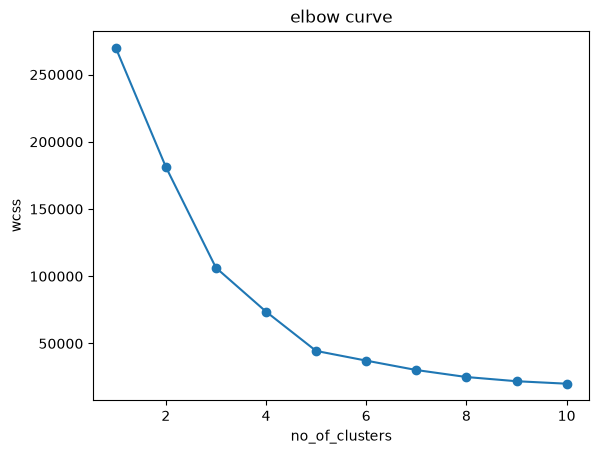

In [24]:
plt.plot(range(1,11),wcss,marker = "o")
plt.title("elbow curve")
plt.xlabel("no_of_clusters")
plt.ylabel("wcss")

In [25]:
kmeans = KMeans(n_clusters = 5, init="k-means++", random_state = 42, n_init = 5)

In [26]:
df['Clusters'] = kmeans.fit_predict(X)

C:\Users\sahil\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [27]:
df[['Annual Income (k$)','Spending Score (1-100)','Clusters']]


,Annual Income (k$),Spending Score (1-100),Clusters
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4
...,...,...,...
195,120,79,1
196,126,28,3
197,126,74,1
198,137,18,3


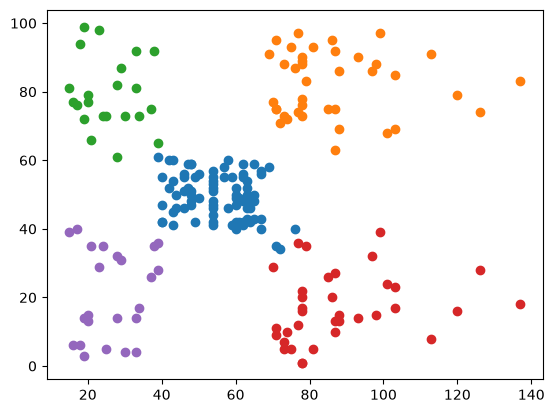

In [33]:
for i in range(5):
    cluster_data = df[df["Clusters"] == i]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {i}"
    )


In [38]:
centeroids = kmeans.cluster_centers_

In [40]:
centeroids

array([[55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [25.72727273, 79.36363636],
       [88.2       , 17.11428571],
       [26.30434783, 20.91304348]])

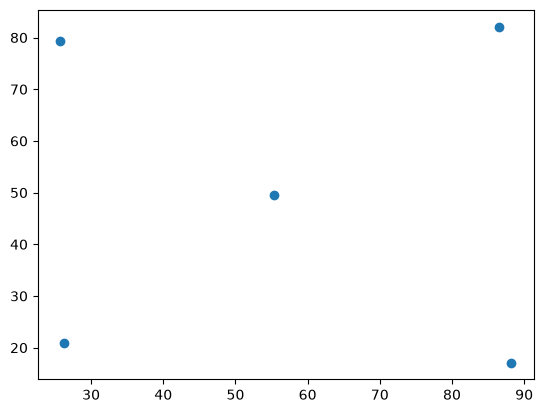

In [48]:
plt.scatter(centeroids[:,0],centeroids[:,1],)

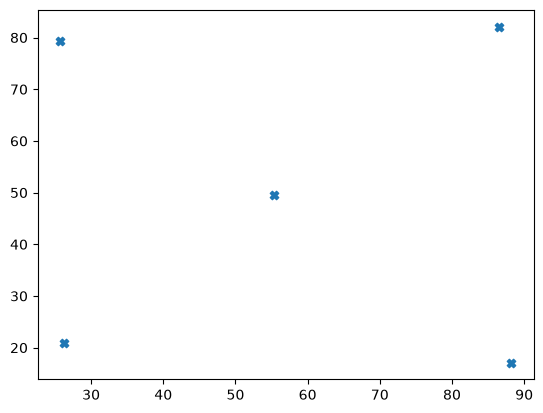